# AirCast — Phase 2: Exploratory Data Analysis & Data Cleaning
**Project:** AirCast — Air Quality Trend Predictor  
**Target Station:** Aotizhongxin (`PRSA_Data_Aotizhongxin_20130301-20170228.csv`)  
**Target Variable:** PM2.5 Concentration (Hourly, $\mu\text{g}/\text{m}^3$)  
**Dataset Source:** Beijing Multi-Site Air Quality Data, UCI Machine Learning Repository  

---

### Notebook Objectives:
1. **Data Inspection:** Validate dimensions, column schemas, types, and summary statistics.
2. **Missingness Audit:** Quantify missingness patterns across pollutants and meteorological variables.
3. **Outage Analysis:** Examine the 343-hour December 2014 sensor failure and justify why interpolation across it is strictly forbidden.
4. **Target Distribution & Spikes:** Analyze PM2.5 skewness, dispersion, and extreme pollution episodes.
5. **Temporal & Seasonal Patterns:** Evaluate seasonal cycles (winter heating vs summer) and diurnal (24-hour) cycles.
6. **Feature Correlations:** Compute Spearman rank correlations among pollutants and meteorological variables.
7. **Conservative Cleaning Execution:** Apply the validated missing-value policy from `src.data_preprocessing`, ensuring zero target fabrication and zero forecasting leakage.
8. **Phase 3 Alignment:** Summarize data constraints and decisions required for feature engineering.

In [1]:
import sys
import os
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Ensure project root and src/ are in sys.path
PROJECT_ROOT = Path(os.path.abspath(".."))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_preprocessing import (
    load_station_data,
    construct_and_verify_timeline,
    summarize_missing_values,
    clean_aotizhongxin_data,
    verify_data_quality,
    compute_file_sha256
)

# Visualization styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["figure.dpi"] = 120

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RAW_CSV_PATH = PROJECT_ROOT / "data" / "raw" / "beijing+multi+site+air+quality+data" / "PRSA2017_Data_20130301-20170228" / "PRSA_Data_20130301-20170228" / "PRSA_Data_Aotizhongxin_20130301-20170228.csv"
CLEANED_CSV_PATH = PROJECT_ROOT / "data" / "processed" / "aotizhongxin_cleaned.csv"

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data file: {RAW_CSV_PATH.name} (Exists: {RAW_CSV_PATH.is_file()})")

Project root: /home/manas/Projects/AirCast
Raw data file: PRSA_Data_Aotizhongxin_20130301-20170228.csv (Exists: True)


## 1. Dataset Loading & Dimension Verification
We load the raw CSV directly and verify that all 18 standard columns are present and that records span the expected 35,064 hourly readings between March 1, 2013 and February 28, 2017.

In [2]:
# Verify raw file SHA-256 hash before reading
initial_hash = compute_file_sha256(str(RAW_CSV_PATH))
print(f"Raw file verified. SHA-256: {initial_hash}")

# Load and verify columns
raw_df = load_station_data(str(RAW_CSV_PATH))
timed_df = construct_and_verify_timeline(raw_df)

print(f"Shape: {timed_df.shape[0]:,} rows x {timed_df.shape[1]} columns")
print(f"Time Range: {timed_df['datetime'].min()} to {timed_df['datetime'].max()} ({len(timed_df):,} hours)")
timed_df.head()

Raw file verified. SHA-256: a94fbcfc71708b6ffdc033360163d91efb7f675e496f6b5860929aa96b96351b
Shape: 35,064 rows x 19 columns
Time Range: 2013-03-01 00:00:00 to 2017-02-28 23:00:00 (35,064 hours)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


In [3]:
# Summary statistics for numeric variables
timed_df.describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]

,count,mean,std,min,25%,50%,75%,max
No,35064.0,17532.5,10122.249256,1.0,8766.75,17532.5,26298.25,35064.0
year,35064.0,2014.66256,1.177213,2013.0,2014.0,2015.0,2016.0,2017.0
month,35064.0,6.52293,3.448752,1.0,4.0,7.0,10.0,12.0
day,35064.0,15.729637,8.800218,1.0,8.0,16.0,23.0,31.0
hour,35064.0,11.5,6.922285,0.0,5.75,11.5,17.25,23.0
PM2.5,34139.0,82.773611,82.135694,3.0,22.0,58.0,114.0,898.0
PM10,34346.0,110.060391,95.223005,2.0,38.0,87.0,155.0,984.0
SO2,34129.0,17.375901,22.823017,0.2856,3.0,9.0,21.0,341.0
NO2,34041.0,59.305833,37.1162,2.0,30.0,53.0,82.0,290.0
CO,33288.0,1262.945145,1221.436236,100.0,500.0,900.0,1500.0,10000.0


## 2. Missing Value Analysis
We calculate the exact missing value counts and proportions across all columns.
- Meteorological variables (`TEMP`, `PRES`, `DEWP`, `RAIN`, `WSPM`) have exceptionally low missingness ($< 0.1\%$).
- Air pollutants exhibit between $2.0\%$ and $5.1\%$ missingness, with Carbon Monoxide (`CO`) having the most missing hours (1,776).
- The target column `PM2.5` is missing for 925 hours ($2.64\%$).

In [4]:
missing_summary = summarize_missing_values(timed_df)
missing_summary

,column,dtype,null_count,null_pct
0,No,int64,0,0.000000
1,year,int64,0,0.000000
2,month,int64,0,0.000000
3,day,int64,0,0.000000
4,hour,int64,0,0.000000
5,PM2.5,float64,925,2.638033
6,PM10,float64,718,2.047684
7,SO2,float64,935,2.666553
8,NO2,float64,1023,2.917522
9,CO,float64,1776,5.065024


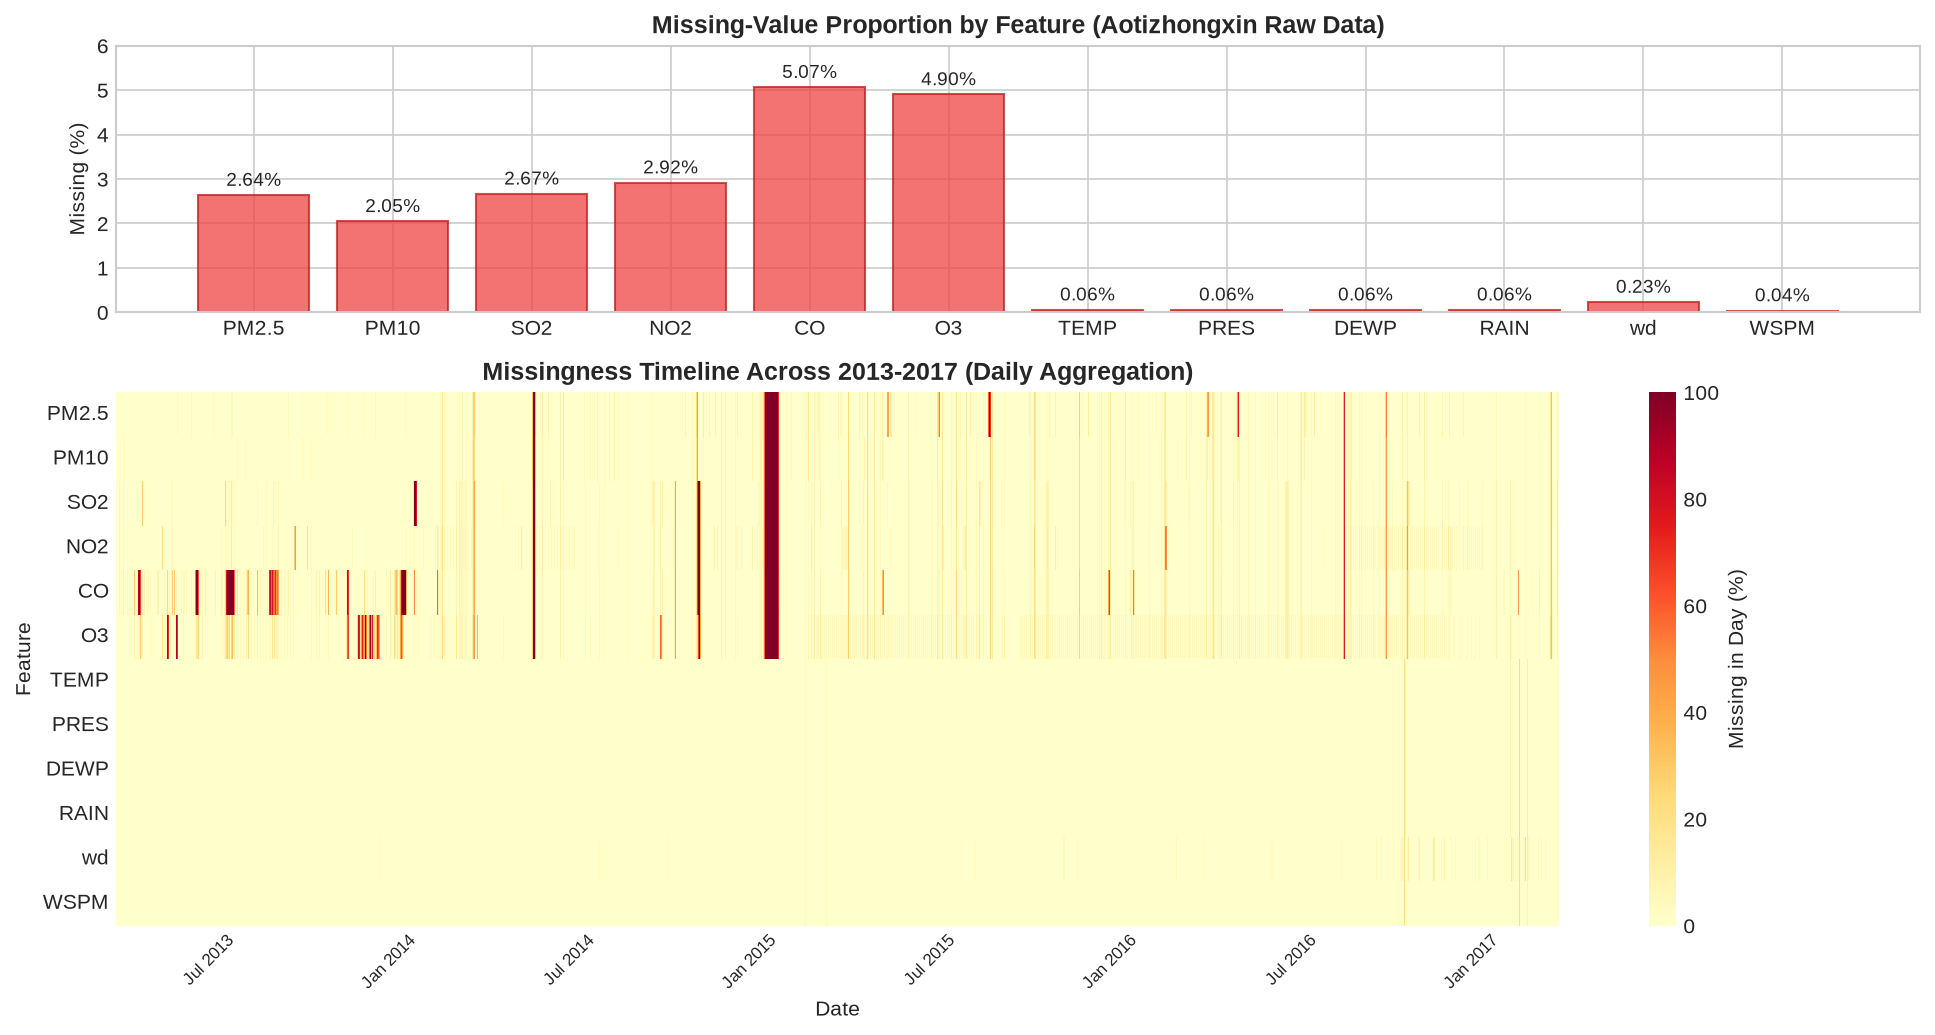

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), dpi=150, gridspec_kw={"height_ratios": [1, 2]})

pollutants_weather = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "wd", "WSPM"]
null_pcts = [timed_df[col].isna().mean() * 100 for col in pollutants_weather]

# Bar plot
bars = ax1.bar(pollutants_weather, null_pcts, color="#ef4444", alpha=0.75, edgecolor="#b91c1c")
ax1.set_ylabel("Missing (%)")
ax1.set_title("Missing-Value Proportion by Feature (Aotizhongxin Raw Data)")
ax1.set_ylim(0, 6.0)
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.12, f"{yval:.2f}%", ha="center", va="bottom", fontsize=9)

# Heatmap over time (daily aggregated)
daily_na = timed_df.set_index("datetime")[pollutants_weather].isna().resample("D").mean() * 100
sns.heatmap(daily_na.T, cmap="YlOrRd", cbar_kws={"label": "Missing in Day (%)"}, ax=ax2)
ax2.set_title("Missingness Timeline Across 2013-2017 (Daily Aggregation)")
ax2.set_xlabel("Date")
ax2.set_ylabel("Feature")

xticks = [i for i, date in enumerate(daily_na.index) if date.day == 1 and date.month in [1, 7]]
xlabels = [daily_na.index[i].strftime("%b %Y") for i in xticks]
ax2.set_xticks(xticks)
ax2.set_xticklabels(xlabels, rotation=45, ha="right", fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "missingness_overview.png", bbox_inches="tight", dpi=300)
plt.show()

## 3. In-Depth Outage Analysis (The Dec 2014 343-Hour Sensor Failure)
A critical finding from Phase 1 was a continuous 343-hour ($14.3$ day) missing block from **2014-12-17 10:00:00** to **2014-12-31 16:00:00**.

### Scientific Justification: Why Interpolation is Strictly Forbidden
1. **Multivariate Sensor Collapse:** All 6 pollutant sensors (`PM2.5`, `PM10`, `SO2`, `NO2`, `CO`, `O3`) failed simultaneously, confirming a station-wide air quality instrumentation blackout.
2. **Weather Remained Active:** During this exact interval, meteorological measurements (`TEMP`, `PRES`, `DEWP`, `RAIN`, `wd`, `WSPM`) were 100% recorded.
3. **High Atmospheric Volatility:** In Beijing winter, air pollution levels can fluctuate from $10\,\mu\text{g}/\text{m}^3$ to $>500\,\mu\text{g}/\text{m}^3$ within a 12-hour period due to passing cold fronts and thermal inversions. Linear, polynomial, or spline interpolation across 14 consecutive days would bridge completely disconnected weather regimes, inventing hundreds of fabricated target labels and corrupting model evaluation.
4. **Policy Decision:** We preserve this entire outage as `NaN`. Downstream training pipelines will drop rows where the target is missing rather than training on hallucinations.

In [6]:
outage_start = "2014-12-17 10:00:00"
outage_end = "2014-12-31 16:00:00"
outage_df = timed_df[(timed_df["datetime"] >= outage_start) & (timed_df["datetime"] <= outage_end)]

print(f"Total outage duration: {len(outage_df)} consecutive hours ({len(outage_df)/24:.1f} days)")
print("\nMissing counts during the Dec 2014 outage window:")
print(outage_df[pollutants_weather].isna().sum())

Total outage duration: 343 consecutive hours (14.3 days)

Missing counts during the Dec 2014 outage window:
PM2.5    343
PM10     343
SO2      343
NO2      343
CO       343
O3       343
TEMP       0
PRES       0
DEWP       0
RAIN       0
wd         0
WSPM       0
dtype: int64


## 4. PM2.5 Target Distribution & Severe Pollution Spikes
We examine the distribution characteristics of PM2.5 concentrations:
- **Skewness:** The distribution is strongly right-skewed ($1.64$), with a heavy upper tail.
- **Central Tendency:** Median is $58.0\,\mu\text{g}/\text{m}^3$, while the Mean is substantially higher at $82.8\,\mu\text{g}/\text{m}^3$ due to acute pollution spikes.
- **Severe Episodes:** The 99th percentile is $377.0\,\mu\text{g}/\text{m}^3$, and the peak observed concentration reaches $898.0\,\mu\text{g}/\text{m}^3$.

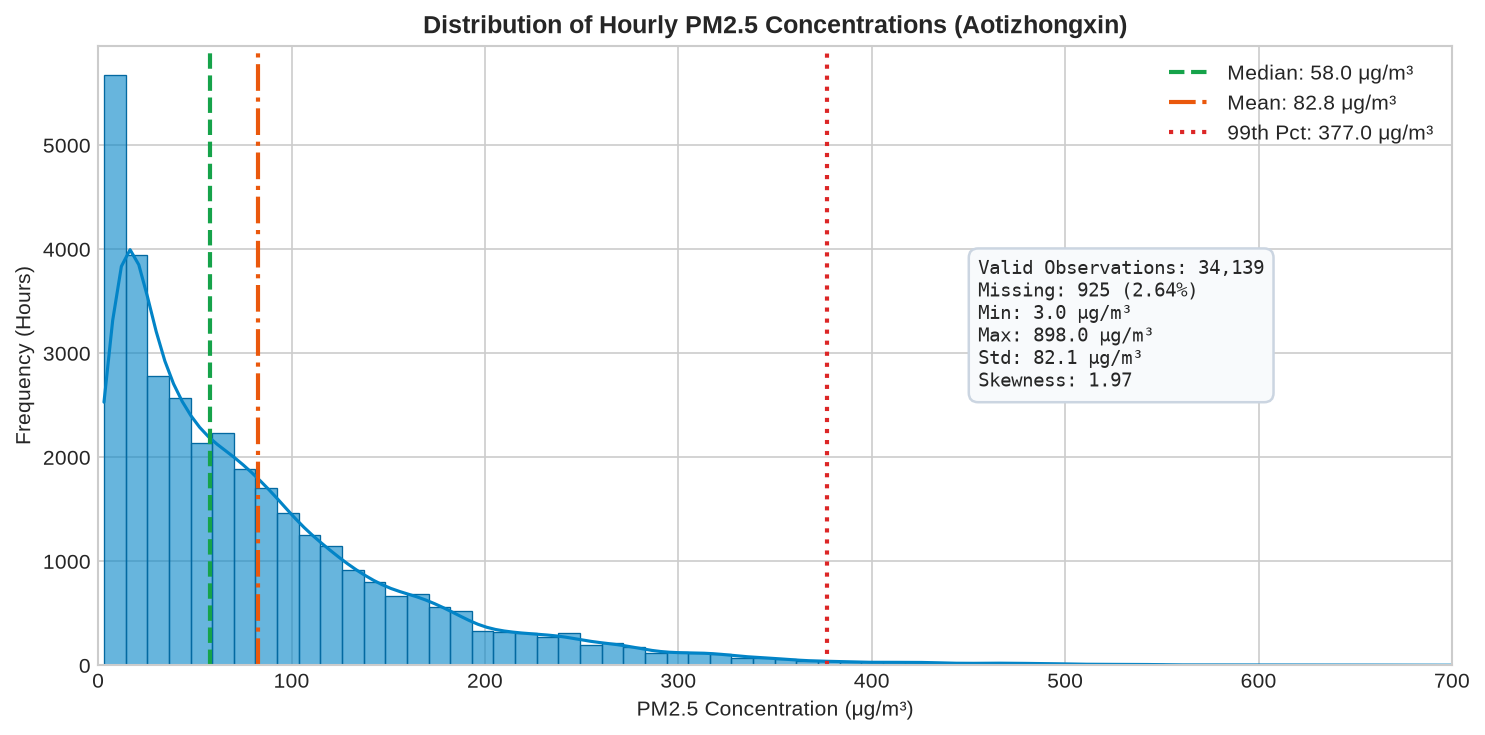

In [7]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
valid_pm = timed_df["PM2.5"].dropna()
sns.histplot(valid_pm, bins=80, kde=True, color="#0284c7", edgecolor="#0369a1", alpha=0.6, ax=ax)

mean_val = valid_pm.mean()
median_val = valid_pm.median()
p99_val = valid_pm.quantile(0.99)

ax.axvline(median_val, color="#16a34a", linestyle="--", linewidth=2, label=f"Median: {median_val:.1f} μg/m³")
ax.axvline(mean_val, color="#ea580c", linestyle="-.", linewidth=2, label=f"Mean: {mean_val:.1f} μg/m³")
ax.axvline(p99_val, color="#dc2626", linestyle=":", linewidth=2, label=f"99th Pct: {p99_val:.1f} μg/m³")

stats_text = (
    f"Valid Observations: {len(valid_pm):,}\n"
    f"Missing: {timed_df['PM2.5'].isna().sum():,} ({timed_df['PM2.5'].isna().mean()*100:.2f}%)\n"
    f"Min: {valid_pm.min():.1f} μg/m³\n"
    f"Max: {valid_pm.max():.1f} μg/m³\n"
    f"Std: {valid_pm.std():.1f} μg/m³\n"
    f"Skewness: {valid_pm.skew():.2f}"
)
ax.text(0.65, 0.45, stats_text, transform=ax.transAxes,
        bbox=dict(boxstyle="round,pad=0.5", facecolor="#f8fafc", edgecolor="#cbd5e1", lw=1.2),
        fontsize=9, family="monospace")

ax.set_title("Distribution of Hourly PM2.5 Concentrations (Aotizhongxin)")
ax.set_xlabel("PM2.5 Concentration (μg/m³)")
ax.set_ylabel("Frequency (Hours)")
ax.set_xlim(0, 700)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pm25_distribution.png", bbox_inches="tight", dpi=300)
plt.show()

## 5. PM2.5 Time-Series Dynamics
Plotting the full 4-year time series reveals pronounced recurrent seasonal cycles:
- **Winter Peaks:** Concentrations regularly exceed $300$–$600\,\mu\text{g}/\text{m}^3$ during November–February.
- **Summer Dips:** Concentrations remain significantly lower during June–August.
- **Notable Event:** The peak concentration of $898\,\mu\text{g}/\text{m}^3$ occurred on **December 1, 2015**, during the historic Beijing heavy smog episode.

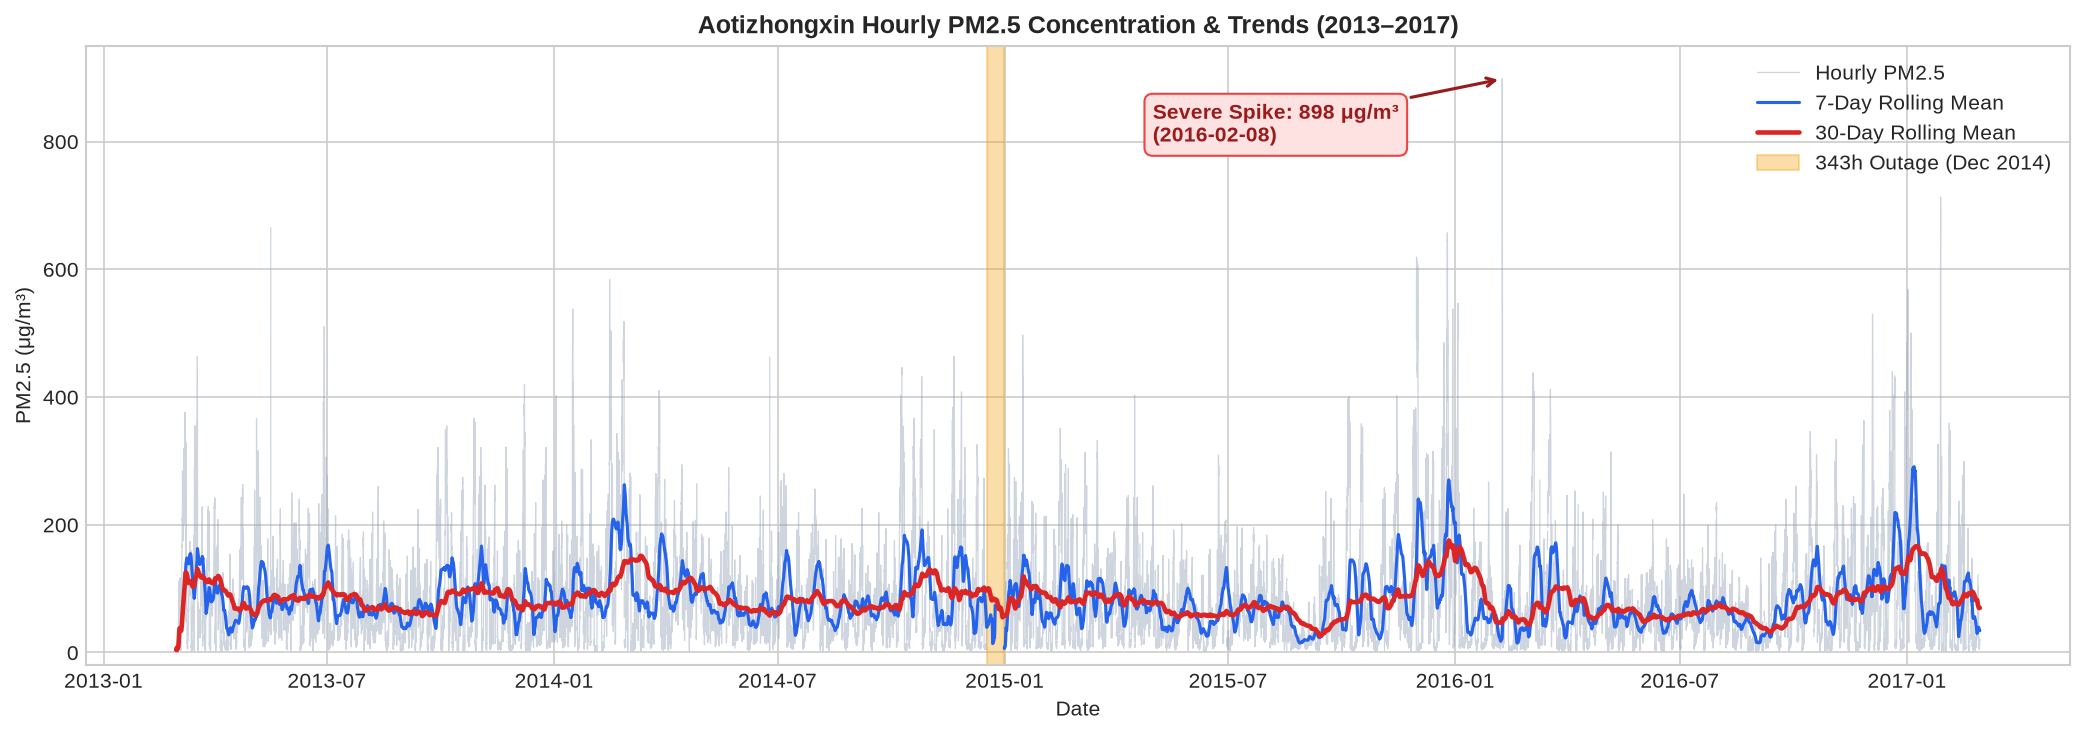

In [8]:
fig, ax = plt.subplots(figsize=(14, 5), dpi=150)
ax.plot(timed_df["datetime"], timed_df["PM2.5"], color="#94a3b8", alpha=0.45, linewidth=0.6, label="Hourly PM2.5")

rolling_7d = timed_df.set_index("datetime")["PM2.5"].rolling("7D").mean()
rolling_30d = timed_df.set_index("datetime")["PM2.5"].rolling("30D").mean()
ax.plot(rolling_7d.index, rolling_7d.values, color="#2563eb", linewidth=1.5, label="7-Day Rolling Mean")
ax.plot(rolling_30d.index, rolling_30d.values, color="#dc2626", linewidth=2.2, label="30-Day Rolling Mean")

# Annotate outage
ax.axvspan(pd.Timestamp("2014-12-17 10:00"), pd.Timestamp("2014-12-31 16:00"), color="#f59e0b", alpha=0.35, label="343h Outage (Dec 2014)")

# Annotate peak episode
max_row = timed_df.loc[timed_df["PM2.5"].idxmax()]
ax.annotate(
    f"Severe Spike: {max_row['PM2.5']:.0f} μg/m³\n({max_row['datetime'].strftime('%Y-%m-%d')})",
    xy=(max_row["datetime"], max_row["PM2.5"]),
    xytext=(pd.Timestamp("2015-05-01"), 800),
    arrowprops=dict(facecolor="#dc2626", edgecolor="#991b1b", arrowstyle="->", lw=1.5),
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#fee2e2", edgecolor="#ef4444", lw=1),
    fontweight="bold", color="#991b1b"
)

ax.set_title("Aotizhongxin Hourly PM2.5 Concentration & Trends (2013–2017)")
ax.set_xlabel("Date")
ax.set_ylabel("PM2.5 (μg/m³)")
ax.set_ylim(-20, 950)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pm25_time_series.png", bbox_inches="tight", dpi=300)
plt.show()

## 6. Seasonal & Diurnal Patterns
Statistical breakdown of PM2.5 across calendar months and hours of the day:
1. **Seasonal Variation:** Winter months (Dec–Feb) average $100$–$115\,\mu\text{g}/\text{m}^3$, driven by centralized coal heating, frequent atmospheric temperature inversions, and lower boundary layer heights. In contrast, summer months (May–Aug) average $60$–$75\,\mu\text{g}/\text{m}^3$ due to greater precipitation scavenging and higher atmospheric mixing.
2. **Diurnal Cycle:** Diurnal concentrations peak around 20:00–23:00 (evening traffic and nighttime inversion trapping) and 08:00–10:00 (morning rush hour), dropping to their lowest levels between 14:00 and 16:00 when solar radiation induces convective mixing and wind speeds increase.

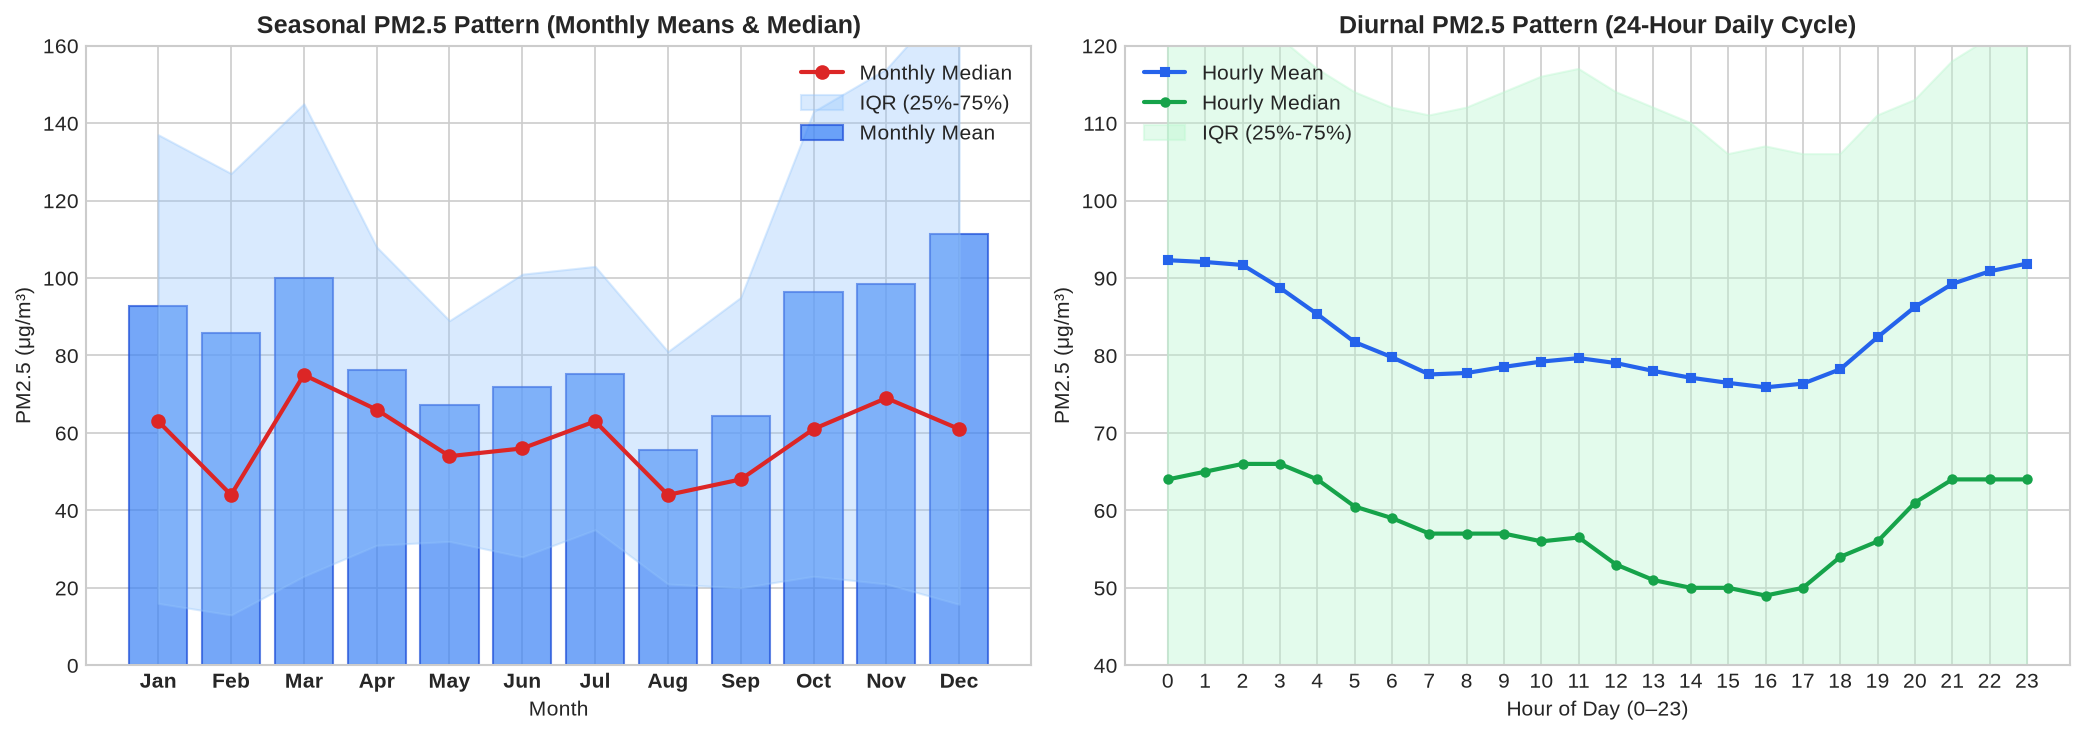

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

month_order = list(range(1, 13))
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly_stats = timed_df.groupby("month")["PM2.5"].agg(["mean", "median", lambda s: s.quantile(0.75), lambda s: s.quantile(0.25)]).reindex(month_order)
monthly_stats.columns = ["mean", "median", "q75", "q25"]

ax1.bar(month_order, monthly_stats["mean"], color="#3b82f6", alpha=0.7, edgecolor="#1d4ed8", label="Monthly Mean")
ax1.plot(month_order, monthly_stats["median"], color="#dc2626", marker="o", linewidth=2, label="Monthly Median")
ax1.fill_between(month_order, monthly_stats["q25"], monthly_stats["q75"], color="#93c5fd", alpha=0.35, label="IQR (25%-75%)")
ax1.set_xticks(month_order)
ax1.set_xticklabels(month_names, fontweight="bold")
ax1.set_title("Seasonal PM2.5 Pattern (Monthly Means & Median)")
ax1.set_xlabel("Month")
ax1.set_ylabel("PM2.5 (μg/m³)")
ax1.legend(loc="upper right")
ax1.set_ylim(0, 160)

# Diurnal
hourly_stats = timed_df.groupby("hour")["PM2.5"].agg(["mean", "median", lambda s: s.quantile(0.75), lambda s: s.quantile(0.25)])
hourly_stats.columns = ["mean", "median", "q75", "q25"]
hours = list(range(24))

ax2.plot(hours, hourly_stats["mean"], color="#2563eb", marker="s", markersize=4, linewidth=2, label="Hourly Mean")
ax2.plot(hours, hourly_stats["median"], color="#16a34a", marker="o", markersize=4, linewidth=2, label="Hourly Median")
ax2.fill_between(hours, hourly_stats["q25"], hourly_stats["q75"], color="#bbf7d0", alpha=0.4, label="IQR (25%-75%)")
ax2.set_xticks(hours)
ax2.set_title("Diurnal PM2.5 Pattern (24-Hour Daily Cycle)")
ax2.set_xlabel("Hour of Day (0–23)")
ax2.set_ylabel("PM2.5 (μg/m³)")
ax2.legend(loc="upper left")
ax2.set_ylim(40, 120)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "seasonal_diurnal_patterns.png", bbox_inches="tight", dpi=300)
plt.show()

## 7. Multi-Pollutant & Meteorological Feature Correlations
We compute the non-parametric **Spearman rank correlation** matrix across numeric features:
- **Strong Co-Pollutant Associations:** PM2.5 exhibits very high rank correlation with `PM10` ($0.88$), `CO` ($0.77$), and `NO2` ($0.67$), confirming shared anthropogenic combustion and vehicle emission origins.
- **Meteorological Drivers:**
  - `WSPM` (Wind speed) has a strong negative correlation ($-0.35$): higher wind speeds actively disperse accumulated pollutants.
  - `DEWP` (Dew point) is positively correlated ($+0.35$): higher moisture/humidity facilitates secondary aerosol formation.
  - `TEMP` has a slight negative overall correlation ($-0.17$), in line with the winter heating peaks.

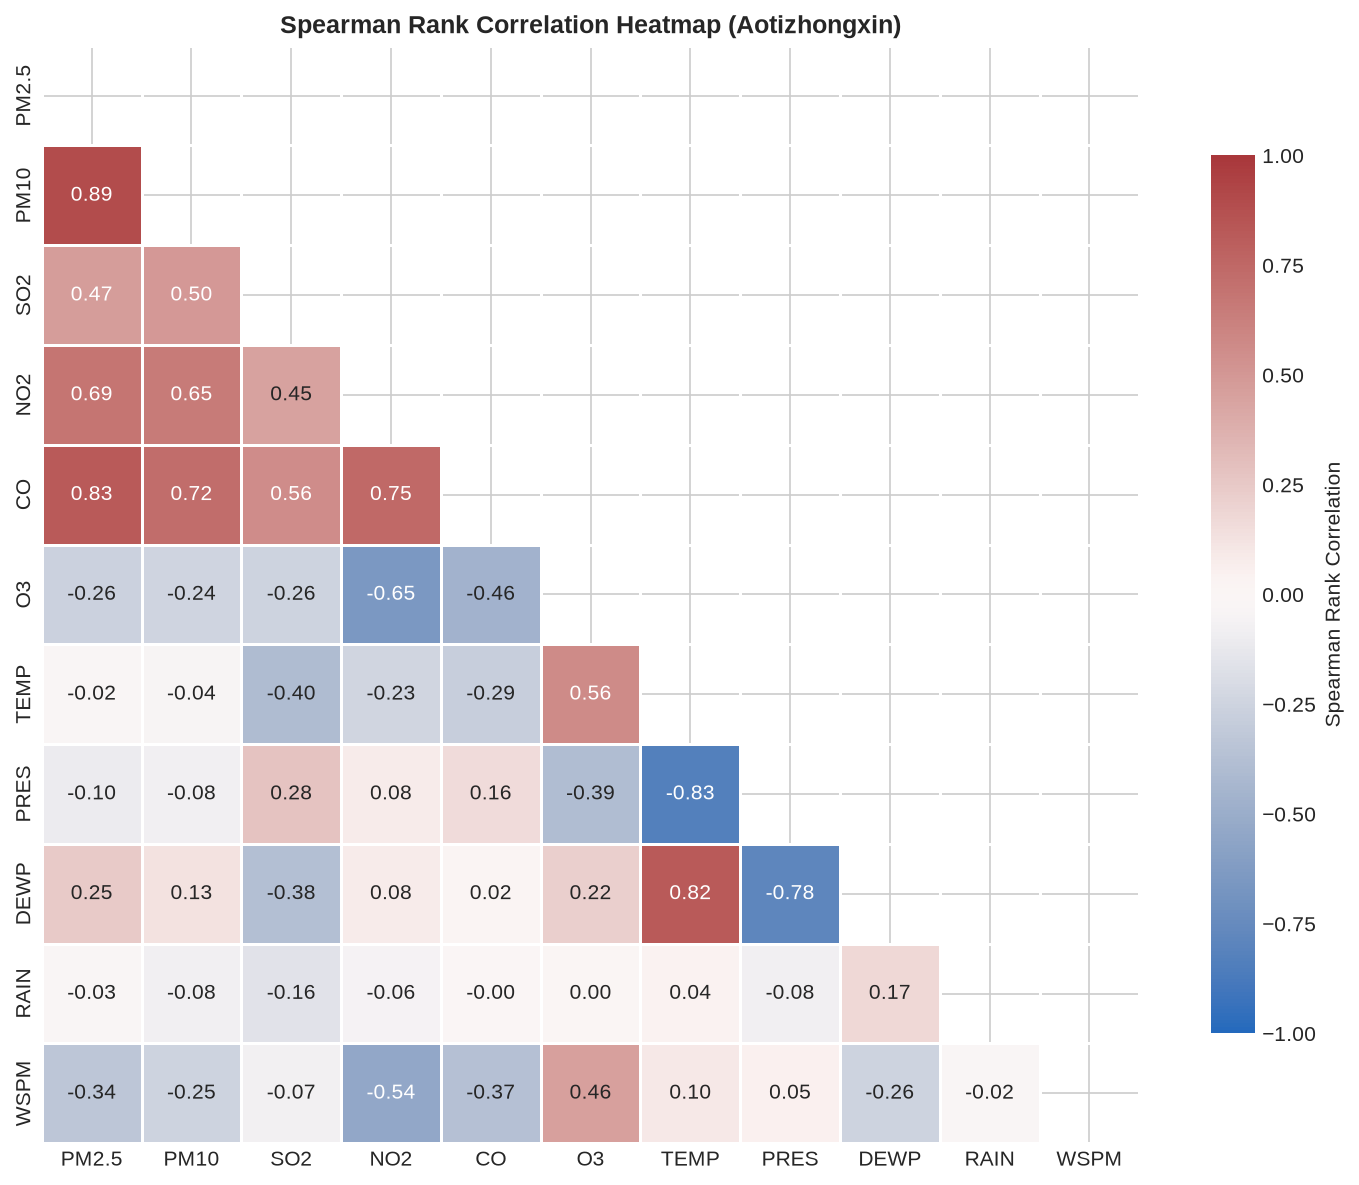

In [10]:
fig, ax = plt.subplots(figsize=(10, 8), dpi=150)
numeric_cols = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
corr = timed_df[numeric_cols].corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, cmap="vlag", vmin=-1.0, vmax=1.0, center=0,
    annot=True, fmt=".2f", square=True, linewidths=0.6,
    cbar_kws={"shrink": 0.8, "label": "Spearman Rank Correlation"},
    ax=ax
)
ax.set_title("Spearman Rank Correlation Heatmap (Aotizhongxin)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "correlation_heatmap.png", bbox_inches="tight", dpi=300)
plt.show()

## 8. Conservative Preprocessing Execution & Quality Assurance
We run the cleaning pipeline from `src.data_preprocessing`:
1. **Target Authenticity:** Zero PM2.5 values are fabricated. All 925 NaNs remain strictly missing.
2. **Leakage Prevention:** Forward-fill is restricted to runs $\le 2$ consecutive hours on input features only.
3. **Outage Preservation:** The entire 343-hour blackout remains `NaN`.
4. **Wind Direction:** Handled explicitly; unfilled values are marked as `'Missing'` without arbitrary ordinal integer encoding.
5. **Traceability:** Original `No` column is retained, and `is_imputed_short_gap` boolean column tracks all imputed rows.
6. **Immutability:** Raw CSV SHA-256 hash is verified identical before and after.

In [11]:
# Execute cleaning
cleaned_df, stats = clean_aotizhongxin_data(timed_df, max_gap_hours=2)

# Verify data quality assertions
verify_data_quality(raw_df, cleaned_df, str(RAW_CSV_PATH), initial_hash)
print("Data quality verification PASSED.")

# Save cleaned output
cleaned_df.to_csv(CLEANED_CSV_PATH, index=False)
print(f"Cleaned dataset saved to: {CLEANED_CSV_PATH} ({len(cleaned_df):,} rows)")

# Display imputation summary
pd.DataFrame(list(stats.items()), columns=["Metric", "Count"])

Data quality verification PASSED.
Cleaned dataset saved to: /home/manas/Projects/AirCast/data/processed/aotizhongxin_cleaned.csv (35,064 rows)


,Metric,Count
0,PM2.5_unfilled_nulls,925
1,PM10_filled,177
2,PM10_remaining_nulls,541
3,SO2_filled,225
4,SO2_remaining_nulls,710
5,NO2_filled,337
6,NO2_remaining_nulls,686
7,CO_filled,361
8,CO_remaining_nulls,1415
9,O3_filled,617


## 9. Summary, Limitations, and Decisions for Phase 3

### Key Findings & Cleaning Summary:
- **Cleaned Dataset:** 35,064 records at strictly hourly intervals from 2013-03-01 to 2017-02-28 saved to `data/processed/aotizhongxin_cleaned.csv`.
- **Target Integrity:** Exactly 925 target observations remain missing as `NaN` ($2.64\%$). No synthetic target values were invented.
- **Leakage-Free Imputation:** Only 1,193 rows had minor 1–2 hour gaps in input features forward-filled. Long sensor blackouts (notably the 343-hour December 2014 outage) were strictly preserved as unobserved.

### Known Limitations:
1. **Localized Station Scope:** Aotizhongxin reflects urban central Beijing; spatial transferability to suburban or mountain stations (e.g. Dingling, Huairou) will require multi-station architectures in future iterations.
2. **Extreme Episodic Tail:** PM2.5 spans up to $898\,\mu\text{g}/\text{m}^3$. Models trained with standard MSE loss may suffer large penalties on these acute peaks.

### Key Decisions Required for Phase 3 (Feature Engineering & Splitting):
1. **Chronological Splitting Scheme:** Establish temporal boundaries (e.g. 2013–2015 Train [~75%], 2016 Validation [~15%], 2017 Test [~10%]) to strictly prevent temporal leakage.
2. **Supervised Target Creation:** Construct $y_t = PM2.5_{t+1}$ (1-hour ahead forecast) and filter out rows where $y_t$ is `NaN` or where lag features span the 343-hour outage.
3. **Lag & Rolling Window Sizes:** Select autoregressive feature windows (e.g., $t-1, t-2, t-3, t-6, t-12, t-24$ and 6h/24h rolling means).
4. **Wind Encoding:** Transform categorical `wd` into continuous circular trigonometric features ($\sin \theta, \cos \theta$).